In [1]:
import hashlib, os, mlflow, pandas as pd, matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

mlflow.set_tracking_uri("http://127.0.0.1:5000")
mlflow.set_experiment("bc-malignant-detection")
os.makedirs("data", exist_ok=True)

df = load_breast_cancer(as_frame=True).frame
df["target"] = 1 - df["target"]          # 1 = malignant (kelas positif)

data_md5 = hashlib.md5(pd.util.hash_pandas_object(df, index=True).values).hexdigest()

train_df, test_df = train_test_split(df, test_size=0.2, stratify=df["target"], random_state=42)
train_df.to_csv("data/train.csv", index=False)
test_df.to_csv("data/test.csv", index=False)   # test set DIKUNCI sampai L6

X_train, y_train = train_df.drop(columns="target"), train_df["target"]
X_test, y_test = test_df.drop(columns="target"), test_df["target"]

train_ds = mlflow.data.from_pandas(train_df, source="data/train.csv", name="bc-train", targets="target")
COMMON_TAGS = {"data_md5": data_md5, "split_seed": "42", "dataset": "sklearn-breast-cancer"}
print(data_md5, train_df.shape, test_df.shape)


C:\Users\user\Documents\bc-mlops\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026/10/08 22:09:46 INFO mlflow.tracking.fluent: Experiment with name 'bc-malignant-detection' does not exist. Creating a new experiment.


ee5481ad12c0896439e993aacc9e8d50 (455, 31) (114, 31)


C:\Users\user\Documents\bc-mlops\.venv\Lib\site-packages\mlflow\data\dataset_source_registry.py:148: UserWarning: The specified dataset source can be interpreted in multiple ways: LocalArtifactDatasetSource, LocalArtifactDatasetSource. MLflow will assume that this is a LocalArtifactDatasetSource source.
  return _dataset_source_registry.resolve(


In [2]:
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from mlflow.models import infer_signature

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
SCORING = ["recall", "precision", "f1", "roc_auc"]

def run_experiment(run_name, pipe, tags=None, note=""):
    with mlflow.start_run(run_name=run_name) as run:
        mlflow.set_tags({**COMMON_TAGS, "candidate": "true", **(tags or {})})
        mlflow.set_tag("mlflow.note.content", note)
        mlflow.log_input(train_ds, context="training")

        mlflow.log_param("pipeline_steps", " -> ".join(pipe.named_steps))
        mlflow.log_params({f"clf__{k}": v for k, v in pipe[-1].get_params().items()})

        cv = cross_validate(pipe, X_train, y_train, cv=CV, scoring=SCORING)
        for m in SCORING:
            mlflow.log_metric(f"cv_{m}_mean", cv[f"test_{m}"].mean())
            mlflow.log_metric(f"cv_{m}_std", cv[f"test_{m}"].std())
        mlflow.log_metric("fit_time_s", cv["fit_time"].mean())

        y_oof = cross_val_predict(pipe, X_train, y_train, cv=CV)
        disp = ConfusionMatrixDisplay.from_predictions(
            y_train, y_oof, display_labels=["benign", "malignant"])
        mlflow.log_figure(disp.figure_, "plots/confusion_matrix_oof.png")
        plt.close(disp.figure_)
        mlflow.log_text(classification_report(y_train, y_oof, zero_division=0),
                        "reports/classification_report_oof.txt")

        pipe.fit(X_train, y_train)
        signature = infer_signature(X_train, pipe.predict(X_train))
        info = mlflow.sklearn.log_model(pipe, name="model", signature=signature,
                    input_example=X_train.head(3),
                    skops_trusted_types=["sklearn.tree._tree.Tree"])
        mlflow.set_tag("model_uri", info.model_uri)
        return run.info.run_id

In [3]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

run_experiment("00-dummy-most-frequent",
    Pipeline([("clf", DummyClassifier(strategy="most_frequent"))]),
    tags={"stage": "baseline", "model_family": "dummy"},
    note="Batas bawah: selalu menebak kelas mayoritas (benign).")

run_experiment("01-logreg-noscale",
    Pipeline([("clf", LogisticRegression(max_iter=5000))]),
    tags={"stage": "baseline", "model_family": "logreg"},
    note="H1: model linear tanpa preprocessing.")

run_experiment("02-logreg-scaled",
    Pipeline([("scaler", StandardScaler()), ("clf", LogisticRegression(max_iter=5000))]),
    tags={"stage": "baseline", "model_family": "logreg"},
    note="H2: hanya menambah StandardScaler, variabel lain tetap.")

C:\Users\user\Documents\bc-mlops\.venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
C:\Users\user\Documents\bc-mlops\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to c

🏃 View run 00-dummy-most-frequent at: http://127.0.0.1:5000/#/experiments/4/runs/26336bba5af74fe382f3ac0f26a3ce7e
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/4


🏃 View run 01-logreg-noscale at: http://127.0.0.1:5000/#/experiments/4/runs/3ab0518490cc42508317510bfbc1f5c8
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/4


🏃 View run 02-logreg-scaled at: http://127.0.0.1:5000/#/experiments/4/runs/cbdb45b7fdf541cf9751e3e88838247b
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/4


'cbdb45b7fdf541cf9751e3e88838247b'

In [5]:
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC

pipe = Pipeline([("scaler", StandardScaler()), ("clf", SVC(kernel="rbf", random_state=42))])
grid = {"clf__C": [0.1, 1, 10, 100], "clf__gamma": ["scale", 0.01, 0.001]}
gs = GridSearchCV(pipe, grid, cv=CV, scoring=SCORING, refit="recall", n_jobs=-1)

with mlflow.start_run(run_name="10-svc-gridsearch",
                      tags={**COMMON_TAGS, "stage": "tuning", "model_family": "svc", "candidate": "true"}):
    mlflow.log_input(train_ds, context="training")
    mlflow.log_dict(grid, "search_space.json")
    gs.fit(X_train, y_train)
    res = gs.cv_results_

    for i, params in enumerate(res["params"]):
        with mlflow.start_run(run_name=f"svc-trial-{i:02d}", nested=True):
            mlflow.log_params(params)
            mlflow.log_metrics({f"cv_{m}_mean": res[f"mean_test_{m}"][i] for m in SCORING})
            mlflow.log_metrics({f"cv_{m}_std": res[f"std_test_{m}"][i] for m in SCORING})

    b = gs.best_index_
    mlflow.log_params(gs.best_params_)
    mlflow.log_metrics({f"cv_{m}_mean": res[f"mean_test_{m}"][b] for m in SCORING})
    mlflow.log_metrics({f"cv_{m}_std": res[f"std_test_{m}"][b] for m in SCORING})
    info = mlflow.sklearn.log_model(gs.best_estimator_, name="model",
        signature=infer_signature(X_train, gs.best_estimator_.predict(X_train)),
        input_example=X_train.head(3))
    mlflow.set_tag("model_uri", info.model_uri)

🏃 View run svc-trial-00 at: http://127.0.0.1:5000/#/experiments/4/runs/4a46d221cb424dbda7c4cc4e0c4cca44
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/4
🏃 View run svc-trial-01 at: http://127.0.0.1:5000/#/experiments/4/runs/9b66af35bbf341999fd1dd71871db133
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/4
🏃 View run svc-trial-02 at: http://127.0.0.1:5000/#/experiments/4/runs/96e413d69a88422db95cf464e39bab95
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/4
🏃 View run svc-trial-03 at: http://127.0.0.1:5000/#/experiments/4/runs/8171de9a9d0140ae9872744c06bf2e44
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/4
🏃 View run svc-trial-04 at: http://127.0.0.1:5000/#/experiments/4/runs/aaedaf52cae1405b98ab6030980d87aa
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/4
🏃 View run svc-trial-05 at: http://127.0.0.1:5000/#/experiments/4/runs/7b34dd86ae1f4e65a804cda29105f3dc
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/4
🏃 View run svc-t

🏃 View run 10-svc-gridsearch at: http://127.0.0.1:5000/#/experiments/4/runs/4626918cec15481aaef14b2c98ece013
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/4


In [6]:
runs = mlflow.search_runs(
    experiment_names=["bc-malignant-detection"],
    filter_string="tags.candidate = 'true' and metrics.cv_precision_mean >= 0.90",
    order_by=["metrics.cv_recall_mean DESC", "metrics.cv_f1_mean DESC"],
)
cols = ["tags.mlflow.runName", "tags.model_family",
        "metrics.cv_recall_mean", "metrics.cv_recall_std", "metrics.cv_precision_mean"]
print(runs[cols].head(5).to_string(index=False))

best_run_id = runs.iloc[0]["run_id"]
best_model_uri = runs.iloc[0]["tags.model_uri"]
print("Kandidat terpilih:", runs.iloc[0]["tags.mlflow.runName"], best_run_id)

tags.mlflow.runName tags.model_family  metrics.cv_recall_mean  metrics.cv_recall_std  metrics.cv_precision_mean
  10-svc-gridsearch               svc                0.964706               0.028818                   0.971092
   02-logreg-scaled            logreg                0.952941               0.039896                   0.977143
  01-logreg-noscale            logreg                0.917647               0.034300                   0.957890
Kandidat terpilih: 10-svc-gridsearch 4626918cec15481aaef14b2c98ece013


{'test_recall': 0.9285714285714286, 'test_precision': 1.0, 'test_f1': 0.9629629629629629, 'test_roc_auc': 0.9927248677248677}


C:\Users\user\Documents\bc-mlops\.venv\Lib\site-packages\mlflow\data\dataset_source_registry.py:148: UserWarning: The specified dataset source can be interpreted in multiple ways: LocalArtifactDatasetSource, LocalArtifactDatasetSource. MLflow will assume that this is a LocalArtifactDatasetSource source.
  return _dataset_source_registry.resolve(
C:\Users\user\Documents\bc-mlops\.venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https:

🏃 View run 10-svc-gridsearch at: http://127.0.0.1:5000/#/experiments/4/runs/4626918cec15481aaef14b2c98ece013
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/4


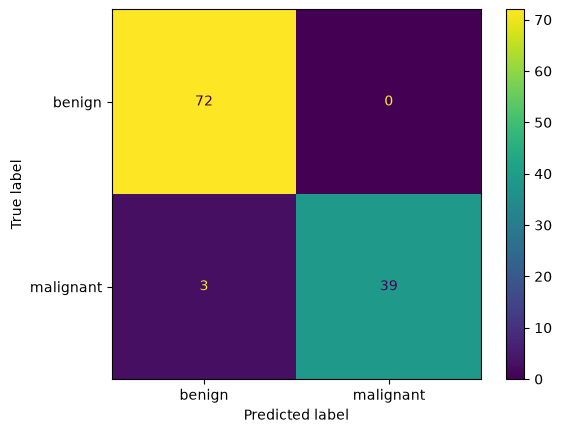

In [7]:
from sklearn.metrics import recall_score, precision_score, f1_score, roc_auc_score

model = mlflow.sklearn.load_model(best_model_uri)
y_pred = model.predict(X_test)
score = (model.predict_proba(X_test)[:, 1] if hasattr(model, "predict_proba")
         else model.decision_function(X_test))

test_metrics = {
    "test_recall":    recall_score(y_test, y_pred),
    "test_precision": precision_score(y_test, y_pred),
    "test_f1":        f1_score(y_test, y_pred),
    "test_roc_auc":   roc_auc_score(y_test, score),
}
print(test_metrics)

with mlflow.start_run(run_id=best_run_id):
    mlflow.log_metrics(test_metrics)
    mlflow.log_input(mlflow.data.from_pandas(test_df, source="data/test.csv",
                     name="bc-test", targets="target"), context="testing")
    disp = ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["benign", "malignant"])
    mlflow.log_figure(disp.figure_, "plots/confusion_matrix_test.png")
    mlflow.set_tag("test_evaluated", "true")

In [8]:
from mlflow import MlflowClient
client, NAME = MlflowClient(), "bc-malignant-classifier"

mv = mlflow.register_model(best_model_uri, NAME)
client.update_model_version(NAME, mv.version,
    description=f"Dipilih otomatis: max cv_recall dgn precision>=0.90. data_md5={data_md5}")
client.set_model_version_tag(NAME, mv.version, "data_md5", data_md5)
client.set_registered_model_alias(NAME, "challenger", mv.version)

def champion_recall():
    try:
        champ = client.get_model_version_by_alias(NAME, "champion")
        return client.get_run(champ.run_id).data.metrics["test_recall"]
    except Exception:
        return -1.0

MIN_PRECISION, MARGIN = 0.90, 0.005
passed = (test_metrics["test_precision"] >= MIN_PRECISION and
          test_metrics["test_recall"] >= champion_recall() + MARGIN)

client.set_model_version_tag(NAME, mv.version, "validation_status", "approved" if passed else "rejected")
if passed:
    client.set_registered_model_alias(NAME, "champion", mv.version)
print("passed:", passed)

Successfully registered model 'bc-malignant-classifier'.
2026/10/08 22:21:33 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: bc-malignant-classifier, version 1
Created version '1' of model 'bc-malignant-classifier'.


passed: True


In [9]:
import requests
payload = {"dataframe_split": X_test.head(3).to_dict(orient="split")}
r = requests.post("http://127.0.0.1:5001/invocations", json=payload)
print(r.json())    # 1 = malignant

{'predictions': [0, 1, 0]}


In [10]:
champ = client.get_model_version_by_alias("bc-malignant-classifier", "champion")
run = client.get_run(champ.run_id)

print("Run        :", run.info.run_name, run.info.run_id)
print("Git commit :", run.data.tags.get("mlflow.source.git.commit"))
print("Data md5   :", run.data.tags["data_md5"])
print("Params     :", {k: v for k, v in run.data.params.items() if k.startswith("clf__")})
print("Metrics    :", {k: round(v, 3) for k, v in run.data.metrics.items()})

assert data_md5 == run.data.tags["data_md5"], "Data berbeda → hasil tidak akan sama!"

path = mlflow.artifacts.download_artifacts(run_id=champ.run_id, artifact_path="model")
print(open(f"{path}/requirements.txt").read())

Run        : 10-svc-gridsearch 4626918cec15481aaef14b2c98ece013
Git commit : None
Data md5   : ee5481ad12c0896439e993aacc9e8d50
Params     : {'clf__C': '10', 'clf__gamma': 'scale'}
Metrics    : {'cv_recall_mean': 0.965, 'cv_precision_mean': 0.971, 'cv_f1_mean': 0.967, 'cv_roc_auc_mean': 0.993, 'cv_recall_std': 0.029, 'cv_precision_std': 0.018, 'cv_f1_std': 0.011, 'cv_roc_auc_std': 0.006, 'test_recall': 0.929, 'test_precision': 1.0, 'test_f1': 0.963, 'test_roc_auc': 0.993}


mlflow==3.17.0
numpy==2.5.3
pandas==3.0.6
psutil==7.2.2
scikit-learn==1.9.1
scipy==1.18.1
skops==0.16.0
